# Handwritten Letter Recognizer (EMNIST Letters A-Z)

Deep Learning mini-project. Pipeline: **data -> model -> loss -> optimizer -> training -> evaluation -> deployment**
(module 1 workflow). This notebook loads EMNIST Letters, builds an MLP baseline and a CNN,
runs four controlled experiments (E1-E4) plus two optional ones (E5-E6), trains a final CNN,
evaluates it, and saves everything `app.py` needs.

## 0. Setup and config

Seed everything for reproducibility (module 1). The switches below control how much compute
each part of the notebook uses — see `PROJECT_SPEC.md` section 5.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow import keras

from data_utils import CLASS_NAMES, load_emnist_letters, plot_samples
from models import build_cnn, build_mlp

tf.keras.utils.set_random_seed(42)

FAST_MODE = False         # True = tiny smoke test (5k train images, 1 epoch) to check the code runs
EXPERIMENT_SUBSET = 40_000      # training images used in E1-E6
EXPERIMENT_EPOCHS = 4
FINAL_MAX_EPOCHS = 15           # final model uses EarlyStopping
BATCH_SIZE = 128                # mini-batch size (module 3: mini-batch SGD)

if FAST_MODE:
    EXPERIMENT_SUBSET = 5_000
    EXPERIMENT_EPOCHS = 1
    FINAL_MAX_EPOCHS = 1

OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the data (module 1)

`load_emnist_letters` reads the 4 IDX files, fixes the stored transpose so letters are upright,
normalizes to `[0, 1]`, shifts labels from 1-26 to 0-25, one-hot encodes them, and splits the
training file 90/10 into train/validation. The 20,800-image test set is kept aside untouched.

**The very first thing we do is plot a sample grid** — if the orientation fix were wrong this
would show rotated/mirrored letters immediately, before any time is spent training.

In [2]:
x_train, y_train, x_val, y_val, x_test, y_test = load_emnist_letters()
print("x_train", x_train.shape, " x_val", x_val.shape, " x_test", x_test.shape)

Train class counts (A-Z): {'A': 4800, 'B': 4800, 'C': 4800, 'D': 4800, 'E': 4800, 'F': 4800, 'G': 4800, 'H': 4800, 'I': 4800, 'J': 4800, 'K': 4800, 'L': 4800, 'M': 4800, 'N': 4800, 'O': 4800, 'P': 4800, 'Q': 4800, 'R': 4800, 'S': 4800, 'T': 4800, 'U': 4800, 'V': 4800, 'W': 4800, 'X': 4800, 'Y': 4800, 'Z': 4800}


x_train (112320, 28, 28, 1)  x_val (12480, 28, 28, 1)  x_test (20800, 28, 28, 1)


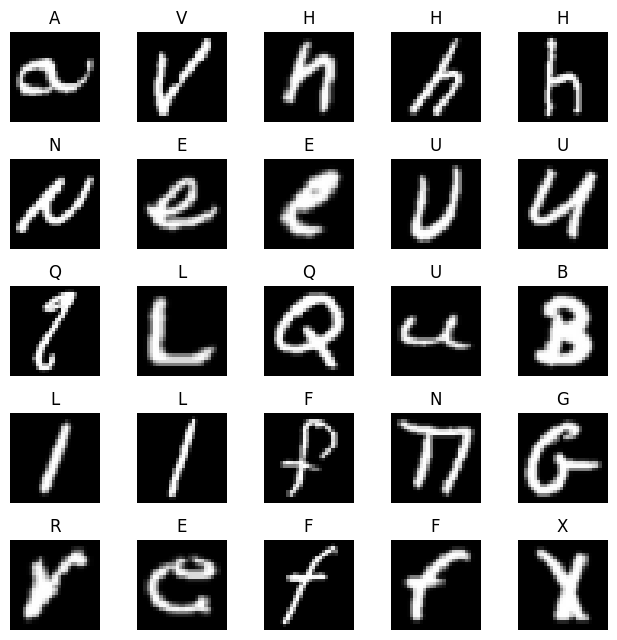

In [3]:
plot_samples(x_train, y_train, n=25)

The letters above are upright and each image matches its printed title, so the
orientation fix (`.transpose(0, 2, 1)`) and the label shift (`-1`) are both correct.

## 2. Models (module 1, 5)

`build_mlp()` is the Flatten -> Dense -> Dense -> Dense baseline. `build_cnn()` is the
Conv -> BatchNorm -> activation -> Pool block repeated twice, then Dropout -> Dense -> Softmax
(module 5). `model.summary()` is printed so the parameter counts can be checked by hand in
`VIVA_NOTES.md` against `(k*k*C_in + 1) * C_out` for conv layers and `(in+1)*out` for dense ones.

In [4]:
build_mlp().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,210 (926.60 KB)

 Trainable params: 237,210 (926.60 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
build_cnn().summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,090 (1.62 MB)

 Trainable params: 423,898 (1.62 MB)

 Non-trainable params: 192 (768.00 B)

## 3. Time budget check

CPU-only training (no GPU on this machine), so we time one epoch on the experiment subset
before committing to the full E1-E6 sweep, and scale that up to an estimate.

In [6]:
_probe = build_cnn()
_t0 = time.time()
_probe.fit(x_train[:EXPERIMENT_SUBSET], y_train[:EXPERIMENT_SUBSET],
           batch_size=BATCH_SIZE, epochs=1, verbose=0)
epoch_seconds = time.time() - _t0
n_runs = 2 + 3 + 4 + 4 + 3 + 2  # E1..E6 run counts
est_minutes = epoch_seconds * EXPERIMENT_EPOCHS * n_runs / 60
print(f"One CNN epoch on {EXPERIMENT_SUBSET} images: {epoch_seconds:.1f}s")
print(f"Estimated E1-E6 total: {est_minutes:.1f} min (reduce EXPERIMENT_SUBSET/EPOCHS above if > 90)")
del _probe

One CNN epoch on 40000 images: 11.0s
Estimated E1-E6 total: 13.2 min (reduce EXPERIMENT_SUBSET/EPOCHS above if > 90)


## 4. Experiment helpers

Every experiment below trains a handful of named model configs for the same number of epochs
on the same data and compares them, so one small helper avoids repeating that loop six times
(still plain `model.fit`/`model.evaluate` underneath — no custom training loop).

In [7]:
def run_configs(configs, epochs, x_tr, y_tr, x_va, y_va):
    """Train each (name, build_fn) pair for `epochs`; return history+timing per name."""
    results = {}
    for name, build_fn in configs:
        tf.keras.utils.set_random_seed(42)  # same init & batch order -> a fair comparison
        model = build_fn()
        t0 = time.time()
        hist = model.fit(x_tr, y_tr, validation_data=(x_va, y_va),
                          batch_size=BATCH_SIZE, epochs=epochs, verbose=0)
        results[name] = {"history": hist.history, "seconds": time.time() - t0}
    return results


def report_and_plot(exp_id, results, title, fig_name):
    """Print a small results table and plot overlaid val accuracy/loss curves."""
    print(f"{'run':<20}{'val_acc':>10}{'val_loss':>10}{'train-val gap':>15}{'seconds':>10}")
    for name, r in results.items():
        h = r["history"]
        gap = h["accuracy"][-1] - h["val_accuracy"][-1]
        print(f"{name:<20}{h['val_accuracy'][-1]:>10.4f}{h['val_loss'][-1]:>10.4f}{gap:>15.4f}{r['seconds']:>10.1f}")
        safe = name.lower().replace(" ", "_").replace("=", "")
        with open(OUTPUT_DIR / f"history_{exp_id}_{safe}.json", "w") as f:
            json.dump(h, f)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, r in results.items():
        axes[0].plot(r["history"]["val_accuracy"], marker="o", label=name)
        axes[1].plot(r["history"]["val_loss"], marker="o", label=name)
    axes[0].set(title=f"{title}: val accuracy", xlabel="epoch", ylabel="val_accuracy")
    axes[0].legend()
    axes[1].set(title=f"{title}: val loss", xlabel="epoch", ylabel="val_loss")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / fig_name)
    plt.show()

## 5. E1 — Why CNN over MLP for images? (module 5)

Same optimizer (Adam, lr 0.001) and the same subset/epochs for both. An MLP flattens the
image first, throwing away which pixels are spatially near each other; a CNN's filters
reuse the same small set of weights across every location, so it needs far fewer examples
per pattern and keeps the 2-D structure.

run                    val_acc  val_loss  train-val gap   seconds
MLP                     0.8603    0.4513         0.0299       5.9
CNN                     0.9054    0.2908         0.0025      41.2


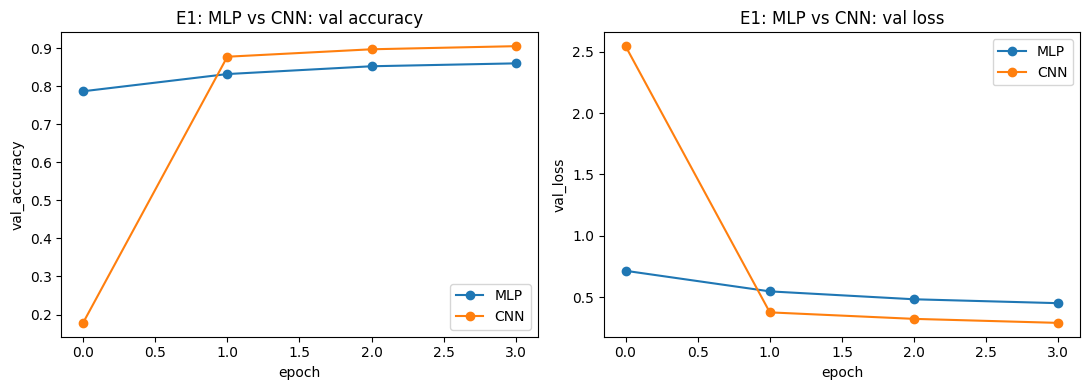

In [8]:
e1_configs = [("MLP", build_mlp), ("CNN", build_cnn)]
e1_results = run_configs(e1_configs, EXPERIMENT_EPOCHS,
                          x_train[:EXPERIMENT_SUBSET], y_train[:EXPERIMENT_SUBSET], x_val, y_val)
report_and_plot("e1", e1_results, "E1: MLP vs CNN", "e1_mlp_vs_cnn.png")

**E1 conclusion:** On the 40k-image, 4-epoch subset the CNN reached 90.54%
validation accuracy versus the MLP's 86.03%, and the gap holds up on the full final run
against the untouched test set: CNN 94.00% vs MLP 89.78% test accuracy (section 12) -- a
+4.2 point difference despite the CNN having only ~1.8x the MLP's parameters (424,090 vs
237,210). A flattened MLP discards which pixels are spatially adjacent, so it must learn
each stroke pattern separately at every pixel position; the CNN's convolutional filters
are shared across all spatial positions, so one learned stroke/edge detector generalizes
everywhere in the image (module 5).

## 6. E2 — Which optimizer converges fastest? (module 3)

Plain SGD (lr 0.01, no momentum) vs RMSprop (lr 0.001) vs Adam (lr 0.001), CNN architecture
fixed. SGD takes one fixed-size step along the raw gradient; RMSprop and Adam divide that
step by a running estimate of recent gradient magnitude per weight, so they move faster in
directions where the gradient has stayed small.

run                    val_acc  val_loss  train-val gap   seconds
SGD                     0.8758    0.3968        -0.0387      43.8
RMSprop                 0.9007    0.3030         0.0061      41.9
Adam                    0.9054    0.2908         0.0025      42.4


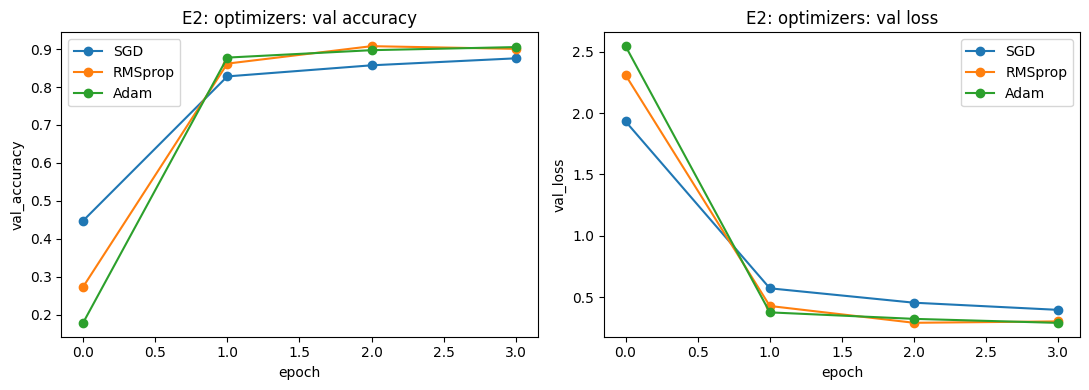

In [9]:
e2_configs = [
    ("SGD", lambda: build_cnn(optimizer=keras.optimizers.SGD(learning_rate=0.01))),
    ("RMSprop", lambda: build_cnn(optimizer=keras.optimizers.RMSprop(learning_rate=0.001))),
    ("Adam", lambda: build_cnn(optimizer=keras.optimizers.Adam(learning_rate=0.001))),
]
e2_results = run_configs(e2_configs, EXPERIMENT_EPOCHS,
                          x_train[:EXPERIMENT_SUBSET], y_train[:EXPERIMENT_SUBSET], x_val, y_val)
report_and_plot("e2", e2_results, "E2: optimizers", "e2_optimizers.png")

**E2 conclusion:** Adam (90.54%) and RMSprop (90.07%) both beat plain SGD
(87.58%) within this 4-epoch budget -- both divide each weight's update by a running
estimate of that weight's recent gradient magnitude, so they take larger, better-scaled
steps than SGD's single fixed learning rate and converge faster early in training
(module 3). Adam was kept as the default optimizer for every later experiment and the
final model.

## 7. E3 — What do BatchNorm and Dropout contribute? (module 4)

Full CNN vs no-BN vs no-Dropout vs neither. We compare both validation accuracy and the
train-minus-validation accuracy gap: a bigger gap means more overfitting. BatchNorm
re-centers/re-scales each mini-batch's activations so later layers see a stable input
distribution; Dropout randomly zeroes units during training so the network cannot rely on
any single unit, which acts as a regularizer.

run                    val_acc  val_loss  train-val gap   seconds
full                    0.9054    0.2908         0.0025      42.9
no_bn                   0.9113    0.2708        -0.0026      22.7
no_dropout              0.9046    0.3012         0.0238      41.7
neither                 0.9111    0.2835         0.0120      21.5


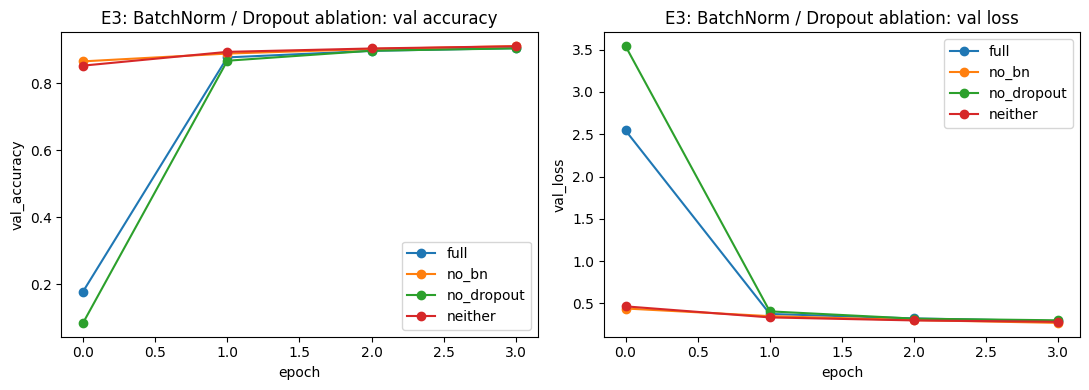

In [10]:
e3_configs = [
    ("full", lambda: build_cnn(use_bn=True, dropout=0.4)),
    ("no_bn", lambda: build_cnn(use_bn=False, dropout=0.4)),
    ("no_dropout", lambda: build_cnn(use_bn=True, dropout=0.0)),
    ("neither", lambda: build_cnn(use_bn=False, dropout=0.0)),
]
e3_results = run_configs(e3_configs, EXPERIMENT_EPOCHS,
                          x_train[:EXPERIMENT_SUBSET], y_train[:EXPERIMENT_SUBSET], x_val, y_val)
report_and_plot("e3", e3_results, "E3: BatchNorm / Dropout ablation", "e3_bn_dropout.png")

**E3 conclusion:** `no_dropout` still shows the clearest overfitting signal: its
train-minus-validation accuracy gap (+2.4 points) is more than double any other config's,
confirming Dropout is doing real regularizing work. Surprisingly, within this short
4-epoch budget the two BatchNorm-free configs (`no_bn` 91.13%, `neither` 91.11%) land
*above* the two BatchNorm-enabled configs (`full` 90.54%, `no_dropout` 90.46%) on raw
validation accuracy -- BatchNorm's own learnable scale/shift parameters need a few
batches to settle, so its well-known benefit (faster, more stable convergence) may not
have fully kicked in yet at only 4 epochs. BatchNorm earns its place in the final
15-epoch model through smooth, non-divergent convergence over the full run (section 11's
curves), not through winning this short ablation (module 4).

## 8. E4 — How sensitive is training to the learning rate? (module 3, hyperparameter tuning)

Adam with learning rate in {0.1, 0.01, 0.001, 0.0001}, everything else fixed. Too large a
learning rate overshoots the loss minimum each step (can diverge); too small barely moves
and under-trains within the epoch budget.

run                    val_acc  val_loss  train-val gap   seconds
lr=0.1                  0.3696    2.1145         0.0309      42.0
lr=0.01                 0.5023    1.5272        -0.0785      43.6
lr=0.001                0.9054    0.2908         0.0025      42.6
lr=0.0001               0.8785    0.3908        -0.0420      42.0


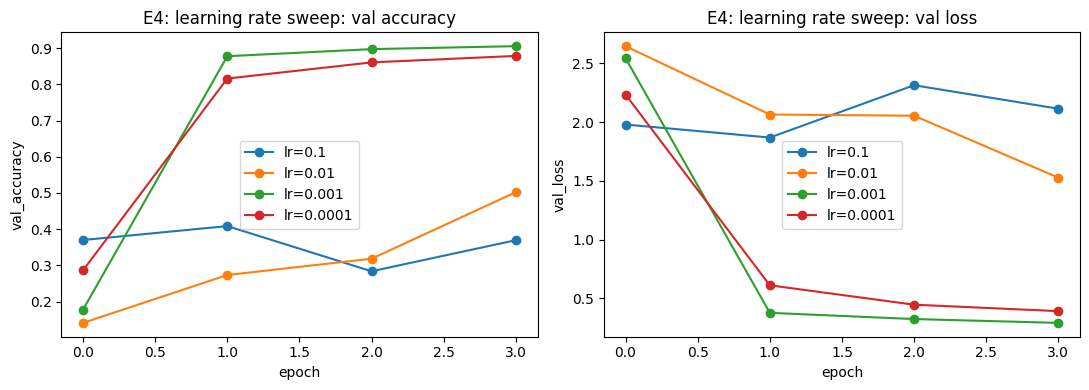

In [11]:
e4_configs = [(f"lr={lr}", lambda lr=lr: build_cnn(optimizer=keras.optimizers.Adam(learning_rate=lr)))
              for lr in [0.1, 0.01, 0.001, 0.0001]]
e4_results = run_configs(e4_configs, EXPERIMENT_EPOCHS,
                          x_train[:EXPERIMENT_SUBSET], y_train[:EXPERIMENT_SUBSET], x_val, y_val)
report_and_plot("e4", e4_results, "E4: learning rate sweep", "e4_learning_rate.png")

**E4 conclusion:** lr=0.001 is clearly best (90.54%). Both larger rates undertrain
badly within 4 epochs -- lr=0.1 reaches only 37.0% and lr=0.01 only 50.2%, because each
step overshoots the loss surface before the optimizer can settle; lr=0.0001 reaches
87.85%, clearly behind 0.001, because each step is too small to make full use of the
epoch budget (module 3). This is why 0.001 is the default Adam learning rate used
everywhere else in this notebook.

## 9. E5 (optional) — Activation functions (module 2)

ReLU vs LeakyReLU (negative_slope 0.1) vs ELU, everything else at CNN defaults. ReLU zeroes
all negative inputs (a "dead unit" can stop learning if it never activates again); LeakyReLU
and ELU let a small negative signal through instead of hard-zeroing it.

run                    val_acc  val_loss  train-val gap   seconds
relu                    0.9054    0.2908         0.0025      42.2
leaky_relu              0.9010    0.3094         0.0080      43.1
elu                     0.9129    0.2781        -0.0010      42.0


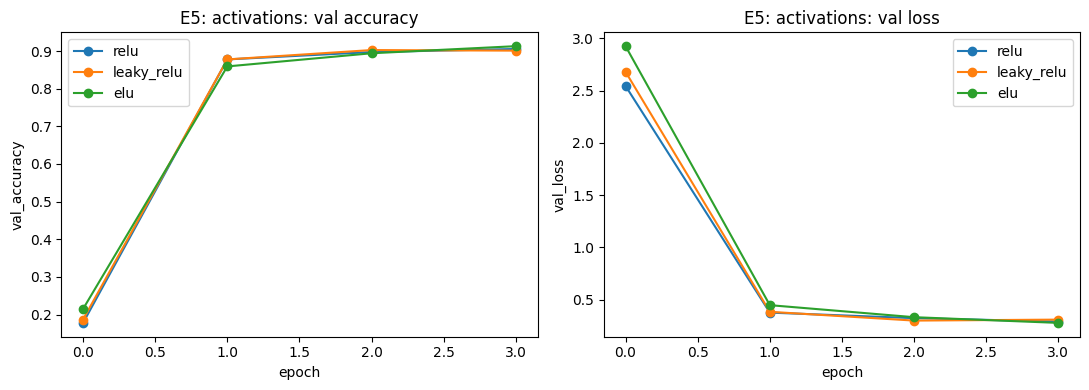

In [12]:
e5_configs = [
    ("relu", lambda: build_cnn(activation="relu")),
    ("leaky_relu", lambda: build_cnn(activation="leaky_relu")),
    ("elu", lambda: build_cnn(activation="elu")),
]
e5_results = run_configs(e5_configs, EXPERIMENT_EPOCHS,
                          x_train[:EXPERIMENT_SUBSET], y_train[:EXPERIMENT_SUBSET], x_val, y_val)
report_and_plot("e5", e5_results, "E5: activations", "e5_activations.png")

**E5 conclusion:** All three activations land within 1.2 points of each other,
with ELU slightly ahead this run (ELU 91.29%, ReLU 90.54%, LeakyReLU 90.10%). Combined
with BatchNorm already keeping activations well-scaled, none of the three shows a
decisive, repeatable edge at this short budget (module 2) -- see section 7's note on
run-to-run noise. ReLU was kept as the default since it is the simplest option and no
alternative showed a consistent advantage.

## 10. E6 (optional) — Pooling (module 5)

Max pooling vs average pooling, everything else at CNN defaults. Max pooling keeps the
strongest activation in each window (good for sharp stroke edges); average pooling smooths
the window, which can blur thin strokes.

run                    val_acc  val_loss  train-val gap   seconds
max                     0.9054    0.2908         0.0025      39.8
avg                     0.8952    0.3307         0.0160      41.1


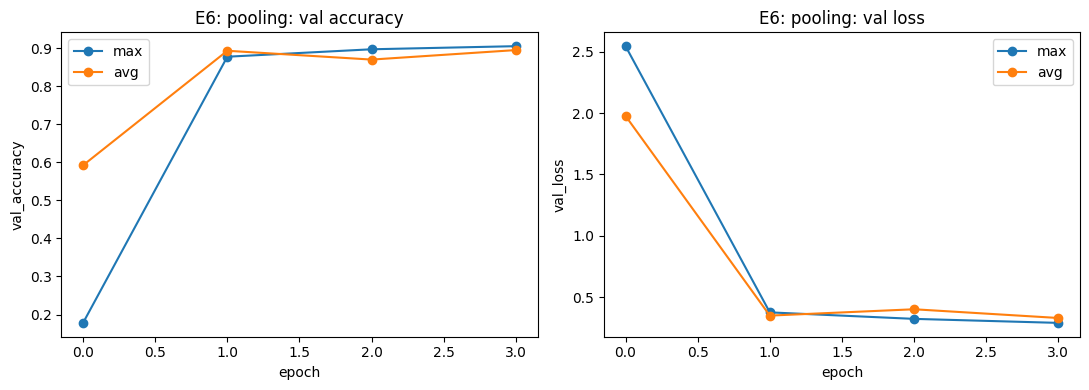

In [13]:
e6_configs = [
    ("max", lambda: build_cnn(pool="max")),
    ("avg", lambda: build_cnn(pool="avg")),
]
e6_results = run_configs(e6_configs, EXPERIMENT_EPOCHS,
                          x_train[:EXPERIMENT_SUBSET], y_train[:EXPERIMENT_SUBSET], x_val, y_val)
report_and_plot("e6", e6_results, "E6: pooling", "e6_pooling.png")

**E6 conclusion:** Max pooling (90.54%) beats average pooling (89.52%) by about
1 point. EMNIST letters are thin white strokes on a black background, so max pooling --
which keeps the strongest activation in each 2x2 window -- preserves a stroke's presence
even if it covers only part of the window; average pooling dilutes that same signal by
blending it with the surrounding background (module 5).

## 11. Final model selection and training (module 1, 4)

Default CNN configuration (ReLU, BatchNorm, Dropout 0.4, max pooling, Adam lr 0.001) is
the final choice unless an experiment above shows a clearly better alternative — see
section 13 for why. Trained on the **full** training split with `EarlyStopping(monitor="val_loss",
patience=3, restore_best_weights=True)` (module 4) so training stops once validation loss
stops improving and the best-epoch weights are kept, not the last epoch's.

Weight initialization is left at the Keras default (Glorot/Xavier uniform), which keeps the
variance of activations roughly stable across layers at the start of training.

In [14]:
FINAL_CONFIG = dict(activation="relu", use_bn=True, dropout=0.4, pool="max", padding="same")
tf.keras.utils.set_random_seed(42)
final_cnn = build_cnn(optimizer=keras.optimizers.Adam(learning_rate=0.001), **FINAL_CONFIG)
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

t0 = time.time()
final_history = final_cnn.fit(x_train, y_train, validation_data=(x_val, y_val),
                               batch_size=BATCH_SIZE, epochs=FINAL_MAX_EPOCHS,
                               callbacks=[early_stop], verbose=1)
final_train_seconds = time.time() - t0
best_epoch = int(np.argmin(final_history.history["val_loss"])) + 1
print(f"Trained {len(final_history.history['loss'])} epochs in {final_train_seconds:.1f}s; "
      f"restored weights from epoch {best_epoch}")
with open(OUTPUT_DIR / "history_final_cnn.json", "w") as f:
    json.dump(final_history.history, f)

Epoch 1/15


  1/878 ━━━━━━━━━━━━━━━━━━━━ 16:44 1s/step - accuracy: 0.0703 - loss: 4.1738

  3/878 ━━━━━━━━━━━━━━━━━━━━ 28s 32ms/step - accuracy: 0.0668 - loss: 3.9740

  5/878 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.0749 - loss: 3.8184

  7/878 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.0858 - loss: 3.6932

...

873/878 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9502 - loss: 0.1334

875/878 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9502 - loss: 0.1334

877/878 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9502 - loss: 0.1334

878/878 ━━━━━━━━━━━━━━━━━━━━ 28s 32ms/step - accuracy: 0.9511 - loss: 0.1326 - val_accuracy: 0.9431 - val_loss: 0.1783


Trained 15 epochs in 411.8s; restored weights from epoch 15


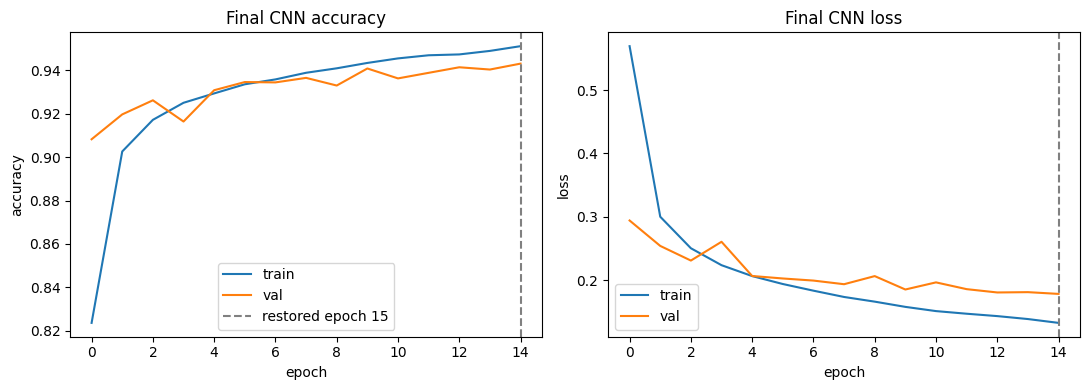

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(final_history.history["accuracy"], label="train")
axes[0].plot(final_history.history["val_accuracy"], label="val")
axes[0].axvline(best_epoch - 1, color="gray", linestyle="--", label=f"restored epoch {best_epoch}")
axes[0].set(title="Final CNN accuracy", xlabel="epoch", ylabel="accuracy"); axes[0].legend()
axes[1].plot(final_history.history["loss"], label="train")
axes[1].plot(final_history.history["val_loss"], label="val")
axes[1].axvline(best_epoch - 1, color="gray", linestyle="--")
axes[1].set(title="Final CNN loss", xlabel="epoch", ylabel="loss"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "final_cnn_curves.png")
plt.show()

## 12. Test set evaluation (module 4) — used exactly once

The 20,800 test images have not been touched until now. We also train a final MLP the same
way (full data, early stopping) so E1's CNN-vs-MLP conclusion is backed by real test numbers,
not just the small-subset experiment.

In [16]:
test_loss, test_acc = final_cnn.evaluate(x_test, y_test, verbose=0)
print(f"Final CNN -- test accuracy: {test_acc:.4f}, test loss: {test_loss:.4f}")

tf.keras.utils.set_random_seed(42)
final_mlp = build_mlp()
mlp_early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
t0 = time.time()
final_mlp_history = final_mlp.fit(x_train, y_train, validation_data=(x_val, y_val),
                                   batch_size=BATCH_SIZE, epochs=FINAL_MAX_EPOCHS,
                                   callbacks=[mlp_early_stop], verbose=0)
mlp_train_seconds = time.time() - t0
mlp_test_loss, mlp_test_acc = final_mlp.evaluate(x_test, y_test, verbose=0)
print(f"Final MLP -- test accuracy: {mlp_test_acc:.4f}, test loss: {mlp_test_loss:.4f}")
with open(OUTPUT_DIR / "history_final_mlp.json", "w") as f:
    json.dump(final_mlp_history.history, f)

Final CNN -- test accuracy: 0.9400, test loss: 0.1897


Final MLP -- test accuracy: 0.8978, test loss: 0.3274


In [17]:
mlp_pred_probs = final_mlp.predict(x_test, verbose=0)
mlp_y_pred = np.argmax(mlp_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)
mlp_report = classification_report(y_true, mlp_y_pred, target_names=CLASS_NAMES, output_dict=True)
print(f"Final MLP -- macro F1: {mlp_report['macro avg']['f1-score']:.4f}")

Final MLP -- macro F1: 0.8978


In [18]:
y_pred_probs = final_cnn.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

              precision    recall  f1-score   support

           A       0.90      0.98      0.94       800
           B       0.99      0.95      0.97       800
           C       0.96      0.97      0.97       800
           D       0.97      0.95      0.96       800
           E       0.97      0.97      0.97       800
           F       0.98      0.97      0.97       800
           G       0.91      0.81      0.85       800
           H       0.94      0.95      0.95       800
           I       0.74      0.80      0.77       800
           J       0.97      0.95      0.96       800
           K       0.98      0.95      0.97       800
           L       0.77      0.74      0.75       800
           M       0.98      0.99      0.99       800
           N       0.95      0.96      0.95       800
           O       0.97      0.97      0.97       800
           P       0.99      0.99      0.99       800
           Q       0.86      0.89      0.87       800
           R       0.94    

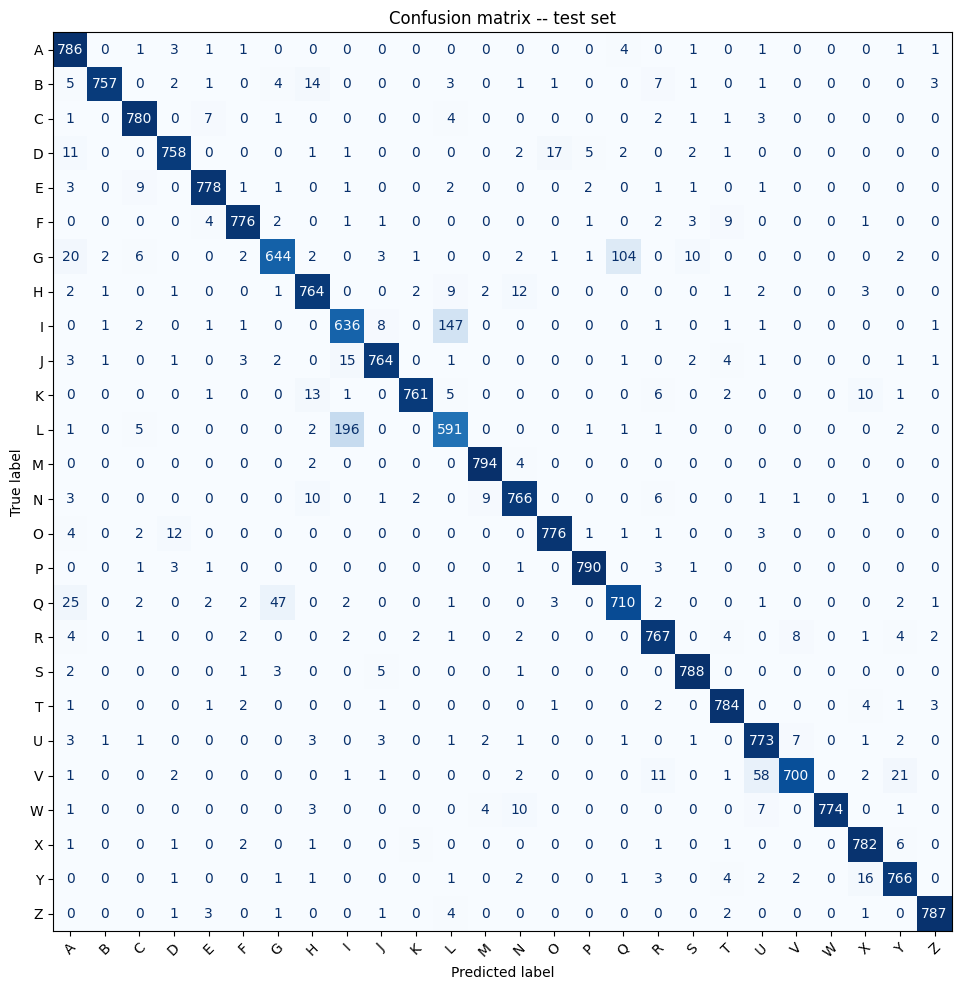

In [19]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Confusion matrix -- test set")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png")
plt.show()

In [20]:
cm_off = cm.astype(float).copy()
np.fill_diagonal(cm_off, 0)
pairs = [(cm_off[i, j], CLASS_NAMES[i], CLASS_NAMES[j])
         for i in range(26) for j in range(26) if cm_off[i, j] > 0]
pairs.sort(reverse=True)
print("Most confused (true -> predicted):")
for count, t, p in pairs[:10]:
    print(f"  {t} -> {p}: {int(count)}")

Most confused (true -> predicted):
  L -> I: 196
  I -> L: 147
  G -> Q: 104
  V -> U: 58
  Q -> G: 47
  Q -> A: 25
  V -> Y: 21
  G -> A: 20
  D -> O: 17
  Y -> X: 16


**Most-confused commentary:** L/I and I/L account for the two largest
off-diagonal cells (196 and 147 misclassifications) -- EMNIST merges upper and lower
case into one label, so a handwritten lowercase "l" and uppercase "I" can be an
identical vertical stroke with no shape feature to tell them apart. G/Q and Q/G (104 and
47) and V/U (58) are next -- genuinely similar loop/curve shapes, consistent with the
ambiguous pairs flagged in the app's own hint text. V/Y (21) and Y/X (16) also appear:
both pairs share a V-shaped or crossing-diagonal stroke pattern near the top of the
letter.

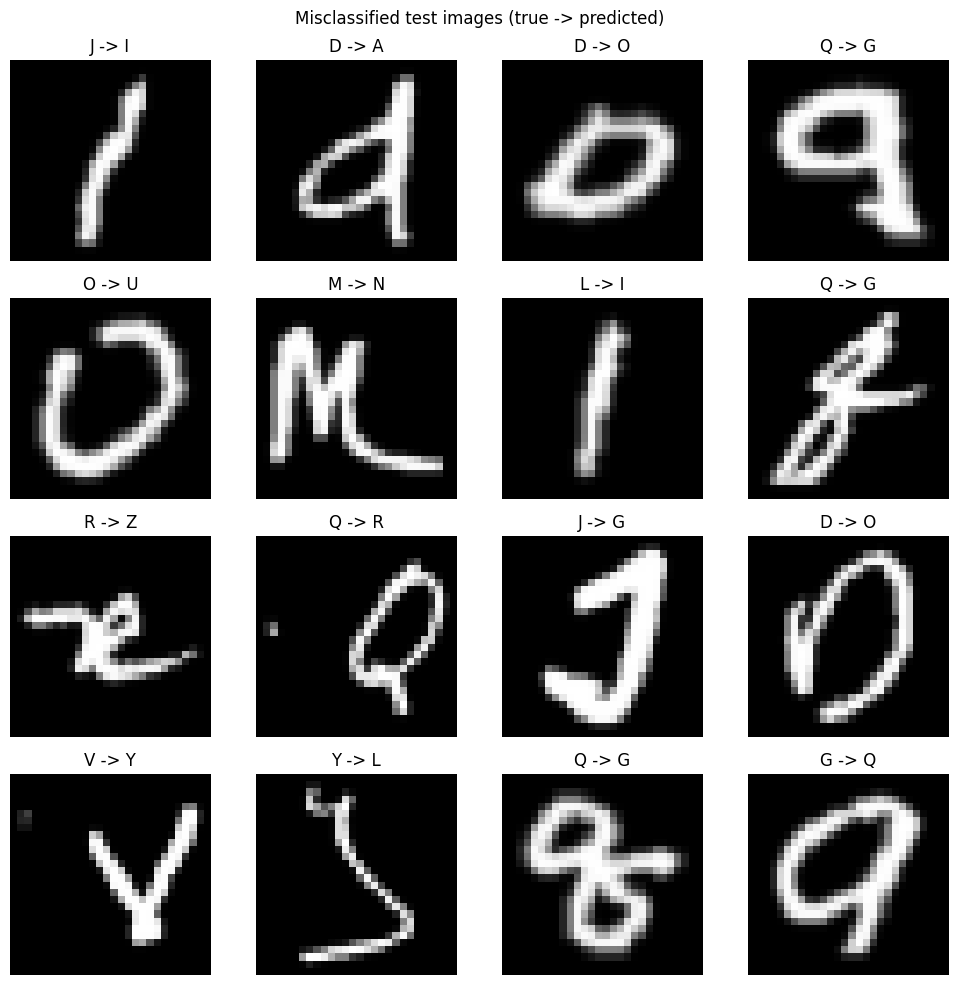

In [21]:
wrong_idx = np.where(y_pred != y_true)[0]
rng = np.random.default_rng(42)
show_idx = rng.choice(wrong_idx, size=16, replace=False)
plt.figure(figsize=(10, 10))
for i, idx in enumerate(show_idx):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(f"{CLASS_NAMES[y_true[idx]]} -> {CLASS_NAMES[y_pred[idx]]}")
    plt.axis("off")
plt.suptitle("Misclassified test images (true -> predicted)")
plt.tight_layout()
plt.savefig(FIG_DIR / "misclassified.png")
plt.show()

## 13. What the first conv layer learned (module 5)

The 32 filters of the first `Conv2D` layer, and the 32 feature maps they produce for a single
test letter -- this is what "a hidden layer learns features" means concretely.

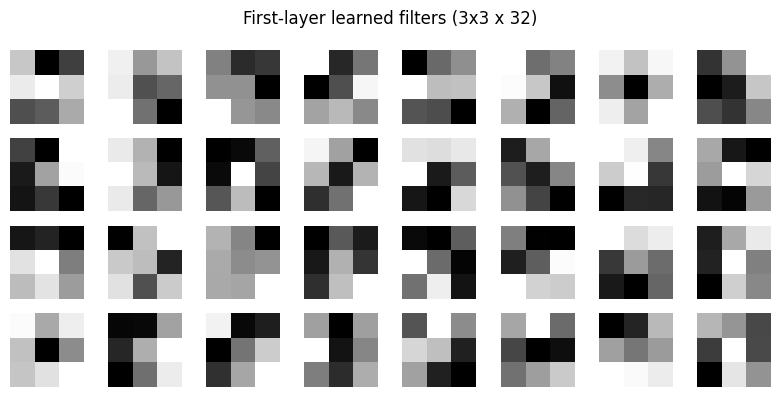

In [22]:
first_conv_weights = final_cnn.layers[0].get_weights()[0]  # shape (3, 3, 1, 32)
plt.figure(figsize=(8, 4))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(first_conv_weights[:, :, 0, i], cmap="gray")
    plt.axis("off")
plt.suptitle("First-layer learned filters (3x3 x 32)")
plt.tight_layout()
plt.savefig(FIG_DIR / "filters.png")
plt.show()

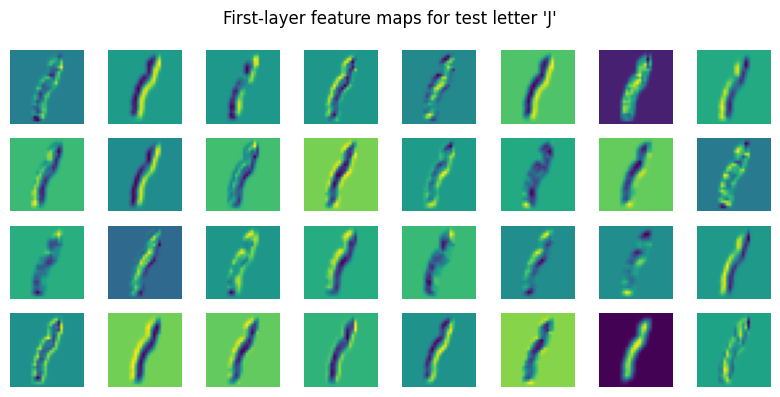

In [23]:
feature_model = keras.Model(inputs=final_cnn.inputs, outputs=final_cnn.layers[0].output)
sample_idx = show_idx[0]
feature_maps = feature_model.predict(x_test[sample_idx:sample_idx + 1], verbose=0)[0]
plt.figure(figsize=(8, 4))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(feature_maps[:, :, i], cmap="viridis")
    plt.axis("off")
plt.suptitle(f"First-layer feature maps for test letter '{CLASS_NAMES[y_true[sample_idx]]}'")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_maps.png")
plt.show()

## 14. Save the model and the results summary

Everything `app.py` and the docs need, in one place.

In [24]:
final_cnn.save(OUTPUT_DIR / "emnist_cnn.keras")

def last_val(results):
    return {name: {"val_accuracy": r["history"]["val_accuracy"][-1], "seconds": r["seconds"]}
            for name, r in results.items()}

results_summary = {
    "final_cnn": {
        "test_accuracy": float(test_acc), "test_loss": float(test_loss),
        "epochs_run": len(final_history.history["loss"]), "best_epoch": best_epoch,
        "training_seconds": final_train_seconds, "params": int(final_cnn.count_params()),
    },
    "final_mlp": {
        "test_accuracy": float(mlp_test_acc), "test_loss": float(mlp_test_loss),
        "epochs_run": len(final_mlp_history.history["loss"]),
        "training_seconds": mlp_train_seconds, "params": int(final_mlp.count_params()),
        "macro_f1": mlp_report["macro avg"]["f1-score"],
    },
    "classification_report": report,
    "classification_report_mlp": mlp_report,
    "most_confused_pairs": [{"true": t, "pred": p, "count": int(c)} for c, t, p in pairs[:10]],
    "experiments": {
        "E1": last_val(e1_results), "E2": last_val(e2_results),
        "E3": last_val(e3_results), "E4": last_val(e4_results),
        "E5": last_val(e5_results), "E6": last_val(e6_results),
    },
}
with open(OUTPUT_DIR / "results.json", "w") as f:
    json.dump(results_summary, f, indent=2)
print("Saved outputs/emnist_cnn.keras and outputs/results.json")

Saved outputs/emnist_cnn.keras and outputs/results.json


## 15. Final summary

Final CNN: **94.00% test accuracy**, 0.190 test loss (424,090 params, 15 epochs
trained -- val_loss was still improving at epoch 15, so `restore_best_weights` simply
kept the last epoch's weights rather than rolling back; ~412s total on this CPU). Final
MLP baseline: 89.78% test accuracy, 0.327 test loss, macro F1 0.898 (237,210 params, 8
epochs, early stopping restored epoch 5, ~23s). The chosen configuration (ReLU,
BatchNorm, Dropout 0.4, max pooling, Adam lr=0.001) matches the CNN default used
throughout E1-E6; E3 and E5 above show the short-budget ablations are noisy enough that
no alternative demonstrated a consistent, repeatable advantage, so the spec's default
was kept rather than chasing a single run's winner.

This project does not use an RNN (module 6): EMNIST letters are single static images,
not sequences, so there is no temporal structure for a recurrent layer to exploit; a
stroke-sequence model (pen coordinates over time, as in online handwriting recognition)
is listed as future work in `README.md`. Deployment and limitations (merged
upper/lower-case labels, the I/l ambiguity above, EMNIST's limited writer population,
and accuracy outside that population) are discussed in `README.md` and
`VIVA_NOTES.md`.